## 1. Configuración

In [ ]:
import os
# --- Corrida -----------------------------------------------------------------
REP = 1                                        # repetición r (1..10)
SEMILLAS = {r: 1000 + r for r in range(1, 11)} # [SUPUESTO] semilla_r = 1000 + r
SEMILLA = SEMILLAS[REP]

MODO_PRUEBA = False        # True: 5 % de los datos y 2 épocas (verificación). False: corrida real.
FRACCION_PRUEBA = 0.05
REANUDAR = True           # reutiliza las etapas ya guardadas en Drive

# --- Rutas -------------------------------------------------------------------
CARPETA = os.environ.get('CARPETA_ARTICULO', '/content/drive/MyDrive/Articulo_Grupal_EdgeIIoT')
RUTA_CSV = os.environ.get('EDGE_CSV', os.path.join(CARPETA, 'DNN-EdgeIIoT-dataset.csv'))
CODIGO = f"REP-{REP:02d}" + ("-PRUEBA" if MODO_PRUEBA else "")
DIR_RUN = os.path.join(CARPETA, 'corridas', CODIGO)

# --- Parámetros fijados por la metodología (sección 13) — no modificar ---------
TEST_SIZE = 0.30
K_GRID = [5, 10, 15, 20, 25, 30]
T_GRID = [2000, 5000, 10000]
RF_GRID = [(n, d) for n in (25, 50, 100) for d in (10, 15, 20)]
XGB_GRID = [(n, d) for n in (50, 100) for d in (4, 6)]
XGB_LR = 0.1
PARSIMONIA = 0.99
CV_PLIEGUES = 3
MI_SUBMUESTRA = 200_000
SMOTE_K = 5
LOTE_MEDICION = 1024
TCN_CFG = dict(lr=1e-3, epocas=50, lote=128, dilataciones=[1, 2, 4, 8], kernel=1,
               filtros=26,       # [SUPUESTO] Gao no reporta filtros; 26 da ≈ 16 KB de parámetros (float32)
               dropout=0.1,      # [SUPUESTO] Gao usa dropout pero no reporta la tasa
               val_split=0.1)    # [SUPUESTO] 10 % del entrenamiento para las curvas de validación
if MODO_PRUEBA:
    TCN_CFG['epocas'] = 2

# Columnas (Gao et al., 2026, secciones 3.2.1, 3.2.2 y apéndice A)
COLS_RETIRAR = ['frame.time', 'ip.dst_host', 'http.file_data', 'ip.src_host', 'arp.src.proto_ipv4',
                'arp.dst.proto_ipv4', 'http.request.full_uri', 'http.request.uri.query',
                'icmp.transmit_timestamp', 'tcp.payload', 'tcp.options', 'tcp.srcport',
                'tcp.dstport', 'udp.port', 'mqtt.msg']
COLS_CATEGORICAS = ['http.request.method', 'http.referer', 'http.request.version',
                    'dns.qry.name.len', 'mqtt.conack.flags', 'mqtt.protoname', 'mqtt.topic']
GAO_18 = ['icmp.checksum', 'icmp.seq_le', 'http.response', 'tcp.ack', 'tcp.ack_raw',
          'tcp.connection.rst', 'tcp.connection.syn', 'udp.stream', 'dns.qry.name',
          'http.request.method-0', 'http.request.method-GET', 'http.request.method-POST',
          'http.referer-0', 'http.request.version-0', 'dns.qry.name.len-0.0',
          'mqtt.conack.flags-0.0', 'mqtt.protoname-0.0', 'mqtt.topic-0.0']

# --- Otros supuestos de implementación -----------------------------------------
REF_CV = (50, 15)          # [SUPUESTO] RF de referencia (árboles, profundidad) para elegir k y luego T
MI_MAX_DISCRETO = 64       # [SUPUESTO] atributo con ≤ 64 valores distintos se trata como discreto
MI_BINS = 32               # [SUPUESTO] si no, se discretiza en 32 intervalos de igual frecuencia
EPISODIO_MIN = 10          # [SUPUESTO] criterio de contigüidad: episodios de ≥ 10 flujos...
FRACCION_CONTIGUA_MIN = 0.5  # ...deben cubrir ≥ 50 % de los flujos de ataque de la prueba
CALENTAMIENTO = 'completo' # pasada de calentamiento descartada: 'completo' o un n.º de lotes

print(CODIGO, '| semilla', SEMILLA, '| salida:', DIR_RUN)

REP-01 | semilla 1001 | salida: /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/corridas/REP-01


## 2. Drive, librerías y entorno de ejecución (tabla 14.2)

In [ ]:
import sys, subprocess, json, time, platform, datetime, io, glob, warnings
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'imbalanced-learn', 'xgboost', 'kagglehub'], check=True)
os.makedirs(DIR_RUN, exist_ok=True)

import numpy as np, pandas as pd, psutil, joblib
import sklearn, imblearn, xgboost, scipy
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=UserWarning)

def guardar_json(obj, nombre):
    with open(os.path.join(DIR_RUN, nombre), 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))

def leer_json(nombre):
    with open(os.path.join(DIR_RUN, nombre), encoding='utf-8') as f:
        return json.load(f)

def existe(nombre):
    return REANUDAR and os.path.exists(os.path.join(DIR_RUN, nombre))

def cpu_modelo():
    try:
        for l in open('/proc/cpuinfo'):
            if l.startswith('model name'):
                return l.split(':', 1)[1].strip()
    except Exception:
        pass
    return platform.processor()

gpus = tf.config.list_physical_devices('GPU')
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
gpu_nombre = 'ninguna'
if gpus:
    try:
        gpu_nombre = subprocess.run(['nvidia-smi', '--query-gpu=name', '--format=csv,noheader'],
                                    capture_output=True, text=True).stdout.strip() or 'GPU'
    except Exception:
        gpu_nombre = 'GPU'
else:
    print('⚠️ No hay GPU: la TCN entrenará en CPU y será muy lenta. Cambia el tipo de entorno a GPU.')

entorno = {
    'codigo_corrida': CODIGO, 'repeticion': REP, 'semilla': SEMILLA,
    'fecha_hora': datetime.datetime.now().strftime('%d/%m/%Y %H:%M'),
    'evaluadores': 'Leonardo Leoncio Villanueva Fonseca; Ricardo Franco Baldoceda Rios',
    'archivo_datos': os.path.basename(RUTA_CSV),
    'procesador': cpu_modelo(), 'nucleos_logicos': psutil.cpu_count(),
    'ram_total_gb': round(psutil.virtual_memory().total / 1024**3, 2),
    'acelerador_entrenamiento_tcn': gpu_nombre,
    'medicion': 'CPU, 1 hilo, lotes de 1024, un proceso por modelo',
    'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
    'scikit_learn': sklearn.__version__, 'imbalanced_learn': imblearn.__version__,
    'xgboost': xgboost.__version__, 'tensorflow': tf.__version__, 'keras': keras.__version__,
    'scipy': scipy.__version__, 'modo_prueba': MODO_PRUEBA,
}
guardar_json(entorno, 'tabla_14_2_entorno.json')
pd.Series(entorno, name='Registro').to_frame()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Registro
codigo_corrida,REP-01
repeticion,1
semilla,1001
fecha_hora,03/11/2026 21:50
evaluadores,Leonardo Leoncio Villanueva Fonseca; Ricardo F...
archivo_datos,DNN-EdgeIIoT-dataset.csv
procesador,Intel(R) Xeon(R) CPU @ 2.00GHz
nucleos_logicos,8
ram_total_gb,50.9900
acelerador_entrenamiento_tcn,Tesla T4


## 3. Carga de Edge-IIoTset (`DNN-EdgeIIoT-dataset.csv`)
Si el archivo no está en Drive, se intenta bajar de Kaggle con `kagglehub` (puede pedir tus credenciales de Kaggle).

In [ ]:
if not os.path.exists(RUTA_CSV):
    import kagglehub
    print('No está en Drive; descargando de Kaggle...')
    ruta = kagglehub.dataset_download('mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot',
                                      path='Edge-IIoTset dataset/Selected dataset for ML and DL/DNN-EdgeIIoT-dataset.csv')
    RUTA_CSV = ruta if ruta.endswith('.csv') else glob.glob(os.path.join(ruta, '**', 'DNN-EdgeIIoT-dataset.csv'), recursive=True)[0]
print('CSV:', RUTA_CSV, f'({os.path.getsize(RUTA_CSV)/1024**2:.0f} MB)')

t0 = time.perf_counter()
cabecera = pd.read_csv(RUTA_CSV, nrows=0).columns.str.strip().tolist()
# Se leen todas las columnas menos las 14 que se retiran; frame.time se lee para guardarla aparte.
retirar_sin_tiempo = [c for c in COLS_RETIRAR if c != 'frame.time']
df = pd.read_csv(RUTA_CSV, low_memory=False, usecols=lambda c: c.strip() not in retirar_sin_tiempo)
df.columns = df.columns.str.strip()
n_bruto = len(df)
print(f'Registros: {n_bruto:,} | columnas en el CSV: {len(cabecera)} (61 atributos + Attack_label + Attack_type)')
print(f'Lectura: {time.perf_counter()-t0:.0f} s')

CSV: /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/DNN-EdgeIIoT-dataset.csv (1161 MB)
Registros: 2,219,201 | columnas en el CSV: 63 (61 atributos + Attack_label + Attack_type)
Lectura: 26 s


## 4. Preprocesamiento común (13.3.1, pasos 1–3)
Se sigue el orden del código de Ferrag et al. (2022) que reproduce Gao et al. (2026): primero se retiran los 15 atributos, luego faltantes y duplicados. `frame.time` se guarda aparte (no entra al modelo).

In [ ]:
t0 = time.perf_counter()
tiempo_bruto = df.pop('frame.time')
n_col_tras_retiro = df.shape[1] - 2          # sin Attack_label ni Attack_type
df = df.dropna(axis=0, how='any')
n_tras_faltantes = len(df)
df = df.drop_duplicates(keep='first')
n_depurado = len(df)
tiempo_bruto = tiempo_bruto.loc[df.index]

# Codificación de los 7 categóricos. Se respetan los nombres de Gao ("columna-valor").
for c in COLS_CATEGORICAS:
    df[c] = df[c].astype(str).str.strip()
dummies = pd.get_dummies(df[COLS_CATEGORICAS], prefix=COLS_CATEGORICAS, prefix_sep='-', dtype=np.float32)
numericas = df.drop(columns=COLS_CATEGORICAS + ['Attack_label', 'Attack_type'])
no_numericas = [c for c in numericas.columns if not pd.api.types.is_numeric_dtype(numericas[c])]
if no_numericas:
    print('⚠️ Columnas no numéricas fuera de las 7 categóricas (se convierten a número):', no_numericas)
    for c in no_numericas:
        numericas[c] = pd.to_numeric(numericas[c], errors='coerce')
X_df = pd.concat([numericas.astype(np.float32), dummies], axis=1)
y_txt = df['Attack_type'].astype(str).str.strip().to_numpy()
del df, numericas, dummies

finitas = np.isfinite(X_df.to_numpy()).all(axis=1)
n_no_finitas = int((~finitas).sum())
if n_no_finitas:
    print(f'⚠️ {n_no_finitas} filas con valores no finitos (NaN/INF tras la conversión): se eliminan')
    X_df, y_txt, tiempo_bruto = X_df[finitas], y_txt[finitas], tiempo_bruto[finitas]

ATRIBUTOS = X_df.columns.tolist()
X = X_df.to_numpy(np.float32)
tiempo_txt = tiempo_bruto.astype(str).to_numpy()
del X_df, tiempo_bruto

le = LabelEncoder().fit(y_txt)
CLASES = le.classes_.tolist()
y = le.transform(y_txt).astype(np.int64)
NORMAL = CLASES.index('Normal')
N_CLASES = len(CLASES)

faltan = [c for c in GAO_18 if c not in ATRIBUTOS]
assert not faltan, f'No se encontraron estos atributos de Gao: {faltan}. Revisa la codificación.'
IDX_GAO = [ATRIBUTOS.index(c) for c in GAO_18]

preproc = {
    'registros_brutos': n_bruto, 'tras_faltantes': n_tras_faltantes, 'registros_depurados': len(y),
    'duplicados_eliminados': n_tras_faltantes - n_depurado, 'filas_no_finitas': n_no_finitas,
    'atributos_tras_retiro': n_col_tras_retiro, 'dimensiones_tras_codificacion': len(ATRIBUTOS),
    'clases': CLASES, 'esperado_gao': {'registros_depurados': 1909671, 'dimensiones': 97},
}
guardar_json(preproc, 'preprocesamiento.json')
pd.Series(ATRIBUTOS).to_csv(os.path.join(DIR_RUN, 'atributos_depurados.csv'), index=False, header=['atributo'])
print(f'Depurados: {len(y):,} flujos (Gao: 1 909 671) | dimensiones: {len(ATRIBUTOS)} (Gao: 97; 94 en su selección)')
print(f'Clases ({N_CLASES}):', CLASES)
print(f'Preprocesamiento: {time.perf_counter()-t0:.0f} s')

Depurados: 1,909,671 flujos (Gao: 1 909 671) | dimensiones: 95 (Gao: 97; 94 en su selección)
Clases (15): ['Backdoor', 'DDoS_HTTP', 'DDoS_ICMP', 'DDoS_TCP', 'DDoS_UDP', 'Fingerprinting', 'MITM', 'Normal', 'Password', 'Port_Scanning', 'Ransomware', 'SQL_injection', 'Uploading', 'Vulnerability_scanner', 'XSS']
Preprocesamiento: 12 s


In [ ]:
# Modo prueba: submuestra estratificada (mín. 300 flujos por clase) para verificar el flujo rápido.
if MODO_PRUEBA:
    rng = np.random.default_rng(SEMILLA)
    sel = []
    for c in range(N_CLASES):
        ids = np.flatnonzero(y == c)
        n = min(len(ids), max(300, int(FRACCION_PRUEBA * len(ids))))
        sel.append(rng.choice(ids, n, replace=False))
    sel = np.sort(np.concatenate(sel))
    X, y, tiempo_txt = X[sel], y[sel], tiempo_txt[sel]
    print(f'MODO PRUEBA: {len(y):,} flujos')

## 5. División 70/30 estratificada y normalización min-max (13.3.1, pasos 4–5)

In [ ]:
idx = np.arange(len(y))
idx_tr, idx_te = train_test_split(idx, test_size=TEST_SIZE, stratify=y, random_state=SEMILLA)
escalador = MinMaxScaler().fit(X[idx_tr])                 # estadísticos solo del entrenamiento
Xtr = escalador.transform(X[idx_tr]).astype(np.float32)
Xte = escalador.transform(X[idx_te]).astype(np.float32)
ytr, yte = y[idx_tr], y[idx_te]
t_te_txt = tiempo_txt[idx_te]
del X

flujos = pd.DataFrame({'Clase': CLASES,
                       'Flujos de entrenamiento': np.bincount(ytr, minlength=N_CLASES),
                       'Flujos de prueba': np.bincount(yte, minlength=N_CLASES)})
flujos.to_csv(os.path.join(DIR_RUN, 'flujos_por_clase.csv'), index=False)
print(f'Entrenamiento: {len(ytr):,} | Prueba: {len(yte):,} | Suma: {len(ytr)+len(yte):,}')
flujos

Entrenamiento: 1,336,769 | Prueba: 572,902 | Suma: 1,909,671


,Clase,Flujos de entrenamiento,Flujos de prueba
0,Backdoor,16818,7208
1,DDoS_HTTP,33981,14563
2,DDoS_ICMP,47557,20382
3,DDoS_TCP,35044,15018
4,DDoS_UDP,85097,36470
5,Fingerprinting,597,256
6,MITM,251,107
7,Normal,954798,409200
8,Password,34953,14980
9,Port_Scanning,13984,5993


## 6. Verificación de episodios para el retardo de detección (13.6)
Se ordena la prueba por `frame.time` y se buscan secuencias continuas de flujos de la misma clase de ataque. Si no forman episodios contiguos, el retardo se declara **no calculable**.

In [ ]:
def parsear_tiempo(s):
    s = pd.Series(s).astype(str).str.strip()
    muestra = s.sample(min(2000, len(s)), random_state=0)
    con_fecha = muestra.str.contains(r'\d{4}-\d{2}-\d{2}|[A-Za-z]{3}\s+\d{1,2}', regex=True).mean() > 0.9
    if con_fecha:
        dt = pd.to_datetime(s, errors='coerce', format='mixed')
        seg = (dt - dt.min()).dt.total_seconds()
        formato = 'fecha y hora'
    else:
        m = s.str.extract(r'(\d{1,2}):(\d{2}):(\d{2}(?:\.\d+)?)')
        seg = m[0].astype(float) * 3600 + m[1].astype(float) * 60 + m[2].astype(float)
        formato = 'solo hora del día (sin fecha)'
    return seg.to_numpy(np.float64), formato

def episodios(t, y_real):
    validos = np.flatnonzero(np.isfinite(t))
    orden = validos[np.argsort(t[validos], kind='mergesort')]
    ys = y_real[orden]
    cambio = np.r_[True, ys[1:] != ys[:-1]]
    ini = np.flatnonzero(cambio)
    fin = np.r_[ini[1:], len(ys)]
    cls = ys[ini]
    m = cls != NORMAL
    return orden, ini[m], fin[m], cls[m]

print('Ejemplos de frame.time:', list(pd.Series(t_te_txt).head(5)))
t_te, formato_tiempo = parsear_tiempo(t_te_txt)
legibles = float(np.isfinite(t_te).mean())
orden_t, ep_ini, ep_fin, ep_cls = episodios(t_te, yte)
largo = ep_fin - ep_ini
frac_contigua = float(largo[largo >= EPISODIO_MIN].sum() / max(largo.sum(), 1))
retardo_calculable = legibles >= 0.99 and frac_contigua >= FRACCION_CONTIGUA_MIN

diag = pd.DataFrame({'Clase': [CLASES[c] for c in ep_cls], 'largo': largo}).groupby('Clase')['largo'] \
         .agg(episodios='count', flujos='sum', mediana_largo='median', max_largo='max')
episodios_info = {'formato_frame_time': formato_tiempo, 'fraccion_legible': legibles,
                  'episodios_de_ataque': int(len(largo)), 'fraccion_flujos_en_episodios_largos': frac_contigua,
                  'criterio': f'>= {FRACCION_CONTIGUA_MIN:.0%} de flujos de ataque en episodios de >= {EPISODIO_MIN} flujos',
                  'retardo_calculable': bool(retardo_calculable)}
guardar_json(episodios_info, 'episodios.json')
diag.to_csv(os.path.join(DIR_RUN, 'episodios_por_clase.csv'))
print(json.dumps(episodios_info, ensure_ascii=False, indent=1))
diag

Ejemplos de frame.time: [' 2021 17:16:59.726972000 ', ' 2021 19:38:19.550360000 ', ' 2021 11:54:45.019390000 ', '182.126.200.126', ' 2021 21:37:20.808317000 ']
{
 "formato_frame_time": "solo hora del día (sin fecha)",
 "fraccion_legible": 0.9361548746557002,
 "episodios_de_ataque": 34251,
 "fraccion_flujos_en_episodios_largos": 0.5537699115044248,
 "criterio": ">= 50% de flujos de ataque en episodios de >= 10 flujos",
 "retardo_calculable": false
}


,episodios,flujos,mediana_largo,max_largo
Clase,,,,
Backdoor,5760,7208,1.0000,6
DDoS_HTTP,1,14563,"14,563.0000",14563
DDoS_ICMP,118,20382,122.0000,2334
DDoS_TCP,3530,15018,3.0000,30
Fingerprinting,216,256,1.0000,2
Password,10913,14980,1.0000,632
Port_Scanning,5111,5993,1.0000,2
Ransomware,1233,2907,1.0000,800
SQL_injection,1149,15248,5.0000,79


## 7. Pre test O₁: TCN de Gao et al. (2026) (13.4.1)
18 atributos del apéndice A, lr 0,001, Adam, PReLU, 50 épocas, lotes de 128, d = 8 (bloques con dilatación 1, 2, 4, 8), w = 1, entropía cruzada categórica, sin balanceo.

**[SUPUESTO]** Con w = 1 la dilatación no amplía el campo receptivo; cada flujo entra como una secuencia de **1 paso con 18 canales**, que es la lectura en la que los 18 atributos llegan a la salida. Cada bloque residual sigue la figura 3 de Gao: convolución causal dilatada → normalización por lotes → PReLU → dropout, con conexión residual (1×1 si cambia el n.º de canales) y activación tras la suma (ecuación 8).

Parámetros: 4,123 ≈ 16.11 KB en float32 (Gao: 16,25 KB)
Epoch 1/50
9400/9400 - 52s - 6ms/step - accuracy: 0.9244 - loss: 0.1792 - val_accuracy: 0.9326 - val_loss: 0.1434
Epoch 2/50
9400/9400 - 31s - 3ms/step - accuracy: 0.9314 - loss: 0.1474 - val_accuracy: 0.9335 - val_loss: 0.1410
Epoch 3/50
9400/9400 - 34s - 4ms/step - accuracy: 0.9320 - loss: 0.1447 - val_accuracy: 0.9336 - val_loss: 0.1388
Epoch 4/50
9400/9400 - 32s - 3ms/step - accuracy: 0.9323 - loss: 0.1430 - val_accuracy: 0.9351 - val_loss: 0.1385
Epoch 5/50
9400/9400 - 32s - 3ms/step - accuracy: 0.9329 - loss: 0.1419 - val_accuracy: 0.9351 - val_loss: 0.1371
Epoch 6/50
9400/9400 - 31s - 3ms/step - accuracy: 0.9335 - loss: 0.1407 - val_accuracy: 0.9353 - val_loss: 0.1367
Epoch 7/50
9400/9400 - 30s - 3ms/step - accuracy: 0.9345 - loss: 0.1389 - val_accuracy: 0.9368 - val_loss: 0.1338
Epoch 8/50
9400/9400 - 31s - 3ms/step - accuracy: 0.9349 - loss: 0.1381 - val_accuracy: 0.9368 - val_loss: 0.1333
Epoch 9/50
9400/9400 - 30s - 3ms

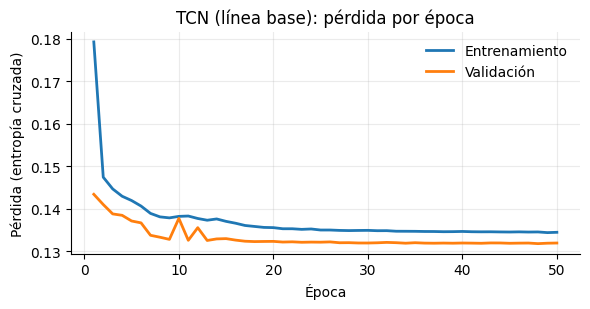

In [ ]:
def construir_tcn(n_atr, n_cls, filtros, kernel, dilataciones, dropout):
    ent = keras.Input(shape=(1, n_atr))
    x = ent
    for d in dilataciones:
        h = layers.Conv1D(filtros, kernel, dilation_rate=d, padding='causal')(x)
        h = layers.BatchNormalization()(h)
        h = layers.PReLU(shared_axes=[1])(h)
        h = layers.Dropout(dropout)(h)
        res = x if x.shape[-1] == filtros else layers.Conv1D(filtros, 1)(x)
        x = layers.PReLU(shared_axes=[1])(layers.Add()([res, h]))
    x = layers.Flatten()(x)
    sal = layers.Dense(n_cls, activation='softmax')(x)
    return keras.Model(ent, sal, name='TCN_Gao2026')

RUTA_TCN = os.path.join(DIR_RUN, 'tcn.keras')
if existe('tcn.keras') and existe('tcn_entrenamiento.json'):
    tcn_info = leer_json('tcn_entrenamiento.json')
    print('Reutilizando TCN guardada:', tcn_info['tiempo_entrenamiento_s'], 's de entrenamiento')
else:
    keras.utils.set_random_seed(SEMILLA)
    tcn = construir_tcn(len(IDX_GAO), N_CLASES, TCN_CFG['filtros'], TCN_CFG['kernel'],
                        TCN_CFG['dilataciones'], TCN_CFG['dropout'])
    tcn.compile(optimizer=keras.optimizers.Adam(TCN_CFG['lr']), loss='categorical_crossentropy', metrics=['accuracy'])
    n_par = tcn.count_params()
    print(f'Parámetros: {n_par:,} ≈ {n_par*4/1024:.2f} KB en float32 (Gao: 16,25 KB)')
    Xtr_tcn = Xtr[:, IDX_GAO].reshape(-1, 1, len(IDX_GAO))
    Ytr = keras.utils.to_categorical(ytr, N_CLASES)
    t0 = time.perf_counter()
    hist = tcn.fit(Xtr_tcn, Ytr, epochs=TCN_CFG['epocas'], batch_size=TCN_CFG['lote'],
                   validation_split=TCN_CFG['val_split'], shuffle=True, verbose=2)
    t_ent = time.perf_counter() - t0
    tcn.save(RUTA_TCN)
    tcn_info = {'tiempo_entrenamiento_s': round(t_ent, 1), 'parametros': n_par,
                'parametros_kb_float32': round(n_par * 4 / 1024, 2), 'config': TCN_CFG,
                'acelerador': gpu_nombre, 'historia': {k: [float(v) for v in vs] for k, vs in hist.history.items()}}
    guardar_json(tcn_info, 'tcn_entrenamiento.json')
    del Xtr_tcn, Ytr
    print(f'Entrenamiento TCN: {t_ent/60:.1f} min')

h = tcn_info['historia']
fig, ax = plt.subplots(figsize=(6, 3.2))
ep = range(1, len(h['loss']) + 1)
ax.plot(ep, h['loss'], lw=2, label='Entrenamiento')
ax.plot(ep, h['val_loss'], lw=2, label='Validación')
ax.set_xlabel('Época'); ax.set_ylabel('Pérdida (entropía cruzada)'); ax.set_title('TCN (línea base): pérdida por época')
ax.grid(alpha=0.25); ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(os.path.join(DIR_RUN, 'fig_tcn_perdida.png'), dpi=200); plt.show()

## 8. Etapa 1: información mutua (13.3.2, ecuaciones 13.2 y 13.3)
I(Y;X) = H(Y) + H(X) − H(Y,X), en bits, estimada solo con el entrenamiento y antes del balanceo, sobre una submuestra estratificada de hasta 200 000 flujos.
**[SUPUESTO]** Atributos con ≤ 64 valores distintos se tratan como discretos; los demás se discretizan en 32 intervalos de igual frecuencia (estimador por conteo).

In [ ]:
def entropia(*codigos):
    c = codigos[0].astype(np.int64)
    for otro in codigos[1:]:                       # entropía conjunta: código combinado
        c = c * (int(otro.max()) + 1) + otro.astype(np.int64)
    _, cnt = np.unique(c, return_counts=True)
    p = cnt / cnt.sum()
    return float(-(p * np.log2(p)).sum())

def discretizar(x):
    u = np.unique(x)
    if len(u) <= MI_MAX_DISCRETO:
        return np.searchsorted(u, x)
    bordes = np.unique(np.quantile(x, np.linspace(0, 1, MI_BINS + 1)[1:-1]))
    return np.digitize(x, bordes)

if existe('mi_ranking.csv'):
    mi_tab = pd.read_csv(os.path.join(DIR_RUN, 'mi_ranking.csv'))
else:
    t0 = time.perf_counter()
    if len(ytr) > MI_SUBMUESTRA:
        sub, _ = train_test_split(np.arange(len(ytr)), train_size=MI_SUBMUESTRA, stratify=ytr, random_state=SEMILLA)
    else:
        sub = np.arange(len(ytr))
    Ys = ytr[sub]; HY = entropia(Ys)
    filas = []
    for j, nombre in enumerate(ATRIBUTOS):
        xc = discretizar(Xtr[sub, j])
        HX = entropia(xc); HYX = entropia(Ys, xc)
        filas.append((nombre, j, HX, HY + HX - HYX))
    mi_tab = pd.DataFrame(filas, columns=['atributo', 'indice', 'H_X_bits', 'IM_bits']) \
               .sort_values('IM_bits', ascending=False, kind='mergesort').reset_index(drop=True)
    mi_tab.insert(0, 'rango', np.arange(1, len(mi_tab) + 1))
    mi_tab.to_csv(os.path.join(DIR_RUN, 'mi_ranking.csv'), index=False)
    print(f'Información mutua: {time.perf_counter()-t0:.0f} s sobre {len(sub):,} flujos; H(Y) = {HY:.3f} bits')
ORDEN_MI = mi_tab['indice'].to_numpy()
mi_tab.head(30)

Información mutua: 1 s sobre 200,000 flujos; H(Y) = 1.817 bits


,rango,atributo,indice,H_X_bits,IM_bits
0,1,mqtt.conack.flags-0.0,77,0.8632,0.8632
1,2,mqtt.protoname-0.0,90,0.8632,0.8632
2,3,mqtt.topic-0.0,93,0.8632,0.8632
3,4,dns.qry.name.len-0.0,67,0.8630,0.8628
4,5,dns.qry.name.len-0,66,0.8644,0.8540
5,6,tcp.ack,8,3.5750,0.8166
6,7,tcp.flags,15,2.4959,0.7019
7,8,mqtt.protoname-0,89,0.9135,0.6797
8,9,mqtt.conack.flags-0,76,0.9141,0.6779
9,10,mqtt.topic-0,92,0.9144,0.6770


## 9. Validación cruzada estratificada de 3 pliegues: k, T e hiperparámetros (13.3.2–13.3.4)
En cada pliegue el balanceo (submuestreo → SMOTE k = 5 → enlaces de Tomek) se aplica **solo** a los pliegues de entrenamiento; el pliegue de validación conserva la distribución natural. Regla de parsimonia: el candidato más pequeño con F1 macro ≥ 99 % del mejor.

**[SUPUESTO]** Búsqueda secuencial con los mismos pliegues: (a) k con T = 5 000 y el RF de referencia (50 árboles, profundidad 15); (b) T con ese k; (c) los 9 RF con k y T elegidos; (d) los 4 XGBoost con el mismo k y T. "Más pequeño" en RF/XGB = menor tamaño serializado medio en los pliegues.

In [ ]:
def balancear(Xs, ys, T, semilla):
    cnt = np.bincount(ys, minlength=N_CLASES)
    bajo = {c: T for c in range(N_CLASES) if cnt[c] > T}
    if bajo:
        Xs, ys = RandomUnderSampler(sampling_strategy=bajo, random_state=semilla).fit_resample(Xs, ys)
    cnt = np.bincount(ys, minlength=N_CLASES)
    sobre = {c: T for c in range(N_CLASES) if 0 < cnt[c] < T}
    if sobre:
        kn = min(SMOTE_K, int(cnt[list(sobre)].min()) - 1)
        if kn < SMOTE_K:
            print(f'   ⚠️ SMOTE con k = {kn} (una clase tiene muy pocos flujos)')
        Xs, ys = SMOTE(sampling_strategy=sobre, k_neighbors=kn, random_state=semilla).fit_resample(Xs, ys)
    Xs, ys = TomekLinks(sampling_strategy='all', n_jobs=-1).fit_resample(Xs, ys)
    return np.ascontiguousarray(Xs, dtype=np.float32), ys

def tamano_kb(modelo):
    b = io.BytesIO(); joblib.dump(modelo, b); return b.tell() / 1024

XGB_DEVICE = 'cpu'   # XGBoost entrena en CPU: un modelo guardado en GPU no se puede cargar en el proceso de medición sin GPU
def nuevo_rf(n, d):
    return RandomForestClassifier(n_estimators=n, max_depth=d, n_jobs=-1, random_state=SEMILLA)
def nuevo_xgb(n, d):
    return XGBClassifier(n_estimators=n, max_depth=d, learning_rate=XGB_LR, tree_method='hist',
                         device=XGB_DEVICE, n_jobs=-1, random_state=SEMILLA, eval_metric='mlogloss')

PLIEGUES = list(StratifiedKFold(CV_PLIEGUES, shuffle=True, random_state=SEMILLA).split(np.zeros(len(ytr)), ytr))
CACHE_BAL = {}
def datos_pliegue(k, T, f):
    if (k, T, f) not in CACHE_BAL:
        a, _ = PLIEGUES[f]
        CACHE_BAL[(k, T, f)] = balancear(Xtr[np.ix_(a, ORDEN_MI[:k])], ytr[a], T, SEMILLA + f)
    return CACHE_BAL[(k, T, f)]

def evaluar_cv(k, T, fabrica):
    f1s, kbs, t0 = [], [], time.perf_counter()
    for f, (_, b) in enumerate(PLIEGUES):
        Xb, yb = datos_pliegue(k, T, f)
        m = fabrica(); m.fit(Xb, yb)
        yp = np.asarray(m.predict(Xtr[np.ix_(b, ORDEN_MI[:k])])).astype(int).ravel()
        f1s.append(f1_score(ytr[b], yp, average='macro', labels=range(N_CLASES), zero_division=0) * 100)
        kbs.append(tamano_kb(m))
    return dict(f1_macro_cv=float(np.mean(f1s)), f1_de=float(np.std(f1s, ddof=1)),
                tamano_kb=float(np.mean(kbs)), segundos=round(time.perf_counter() - t0, 1))

def parsimonia(tabla, criterio):
    mejor = tabla['f1_macro_cv'].max()
    tabla['cumple_99'] = tabla['f1_macro_cv'] >= PARSIMONIA * mejor
    return tabla[tabla['cumple_99']].sort_values(criterio, kind='mergesort').iloc[0]

def etapa_cv(nombre, candidatos, fabrica_de, criterio):
    archivo = f'cv_{nombre}.csv'
    if existe(archivo):
        tabla = pd.read_csv(os.path.join(DIR_RUN, archivo))
    else:
        filas = []
        for cand in candidatos:
            k, T, fab, etiqueta = fabrica_de(cand)
            r = evaluar_cv(k, T, fab); r.update(etiqueta)
            filas.append(r)
            print(f'  {nombre} {etiqueta}: F1 macro CV = {r["f1_macro_cv"]:.2f} % | {r["tamano_kb"]:.0f} KB | {r["segundos"]} s')
        tabla = pd.DataFrame(filas)
    elegido = parsimonia(tabla, criterio)
    tabla.to_csv(os.path.join(DIR_RUN, archivo), index=False)
    return tabla, elegido

(a) Selección de k
  k {'k': 5}: F1 macro CV = 12.07 % | 72 KB | 302.1 s
  k {'k': 10}: F1 macro CV = 59.81 % | 8571 KB | 40.5 s
  k {'k': 15}: F1 macro CV = 69.18 % | 7855 KB | 45.1 s
  k {'k': 20}: F1 macro CV = 83.85 % | 12481 KB | 27.3 s
  k {'k': 25}: F1 macro CV = 90.74 % | 7474 KB | 28.0 s
  k {'k': 30}: F1 macro CV = 90.86 % | 8138 KB | 28.2 s
   → k = 25
(b) Selección de T
  T {'T': 2000}: F1 macro CV = 90.50 % | 5856 KB | 7.7 s
  T {'T': 5000}: F1 macro CV = 90.74 % | 7474 KB | 4.5 s
  T {'T': 10000}: F1 macro CV = 90.85 % | 8917 KB | 92.0 s
   → T = 2000
(c) Hiperparámetros del Random Forest
  rf {'arboles': 25, 'profundidad': 10}: F1 macro CV = 87.56 % | 806 KB | 2.1 s
  rf {'arboles': 25, 'profundidad': 15}: F1 macro CV = 90.46 % | 2919 KB | 2.2 s
  rf {'arboles': 25, 'profundidad': 20}: F1 macro CV = 89.70 % | 5935 KB | 2.2 s
  rf {'arboles': 50, 'profundidad': 10}: F1 macro CV = 87.18 % | 1562 KB | 3.7 s
  rf {'arboles': 50, 'profundidad': 15}: F1 macro CV = 90.50 % | 58

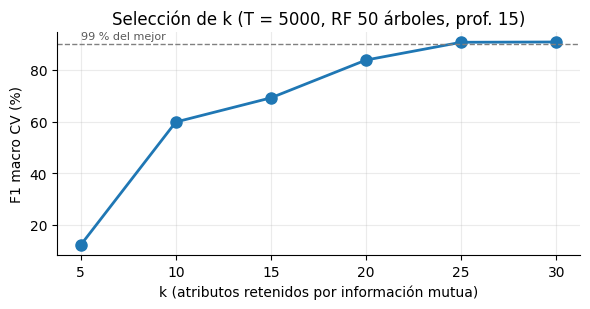

In [ ]:
t_cv = time.perf_counter()
T0 = 5000
print('(a) Selección de k')
cv_k, sel_k = etapa_cv('k', K_GRID, lambda k: (k, T0, lambda: nuevo_rf(*REF_CV), {'k': k}), 'k')
K = int(sel_k['k'])
print('   → k =', K)

print('(b) Selección de T')
cv_T, sel_T = etapa_cv('T', T_GRID, lambda T: (K, T, lambda: nuevo_rf(*REF_CV), {'T': T}), 'T')
T_SEL = int(sel_T['T'])
print('   → T =', T_SEL)

print('(c) Hiperparámetros del Random Forest')
cv_rf, sel_rf = etapa_cv('rf', RF_GRID, lambda c: (K, T_SEL, lambda: nuevo_rf(*c), {'arboles': c[0], 'profundidad': c[1]}), 'tamano_kb')
RF_SEL = (int(sel_rf['arboles']), int(sel_rf['profundidad']))
print('   → RF', RF_SEL)

print('(d) Hiperparámetros de XGBoost')
cv_xgb, sel_xgb = etapa_cv('xgb', XGB_GRID, lambda c: (K, T_SEL, lambda: nuevo_xgb(*c), {'arboles': c[0], 'profundidad': c[1]}), 'tamano_kb')
XGB_SEL = (int(sel_xgb['arboles']), int(sel_xgb['profundidad']))
print('   → XGB', XGB_SEL)

seleccion = {'k': K, 'T': T_SEL, 'rf_arboles': RF_SEL[0], 'rf_profundidad': RF_SEL[1],
             'xgb_arboles': XGB_SEL[0], 'xgb_profundidad': XGB_SEL[1], 'xgb_lr': XGB_LR,
             'atributos_k': [ATRIBUTOS[j] for j in ORDEN_MI[:K]]}
if not existe('seleccion.json'):
    seleccion['tiempo_cv_s'] = round(time.perf_counter() - t_cv, 1)
    guardar_json(seleccion, 'seleccion.json')
else:
    seleccion['tiempo_cv_s'] = leer_json('seleccion.json').get('tiempo_cv_s')
print(json.dumps(seleccion, ensure_ascii=False, indent=1))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(cv_k['k'], cv_k['f1_macro_cv'], lw=2, marker='o', ms=8)
ax.axhline(PARSIMONIA * cv_k['f1_macro_cv'].max(), lw=1, ls='--', color='0.5')
ax.annotate('99 % del mejor', (cv_k['k'].iloc[0], PARSIMONIA * cv_k['f1_macro_cv'].max()),
            textcoords='offset points', xytext=(0, 4), fontsize=8, color='0.35')
ax.set_xlabel('k (atributos retenidos por información mutua)'); ax.set_ylabel('F1 macro CV (%)')
ax.set_title(f'Selección de k (T = {T0}, RF {REF_CV[0]} árboles, prof. {REF_CV[1]})')
ax.set_xticks(K_GRID); ax.grid(alpha=0.25); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(os.path.join(DIR_RUN, 'fig_seleccion_k.png'), dpi=200); plt.show()

## 10. Post test O₂: entrenamiento final de Random Forest y XGBoost (joblib)

In [ ]:
RUTA_RF = os.path.join(DIR_RUN, 'rf.joblib')
RUTA_XGB = os.path.join(DIR_RUN, 'xgb.joblib')
COLS_K = ORDEN_MI[:K]
if existe('rf.joblib') and existe('xgb.joblib') and existe('finales.json') and leer_json('finales.json').get('xgb_device') == 'cpu':
    finales = leer_json('finales.json')
else:
    t0 = time.perf_counter()
    Xb, yb = balancear(Xtr[:, COLS_K], ytr, T_SEL, SEMILLA)
    t_bal = time.perf_counter() - t0
    finales = {'flujos_entrenamiento_balanceado': int(len(yb)), 'tiempo_balanceo_s': round(t_bal, 1), 'xgb_device': XGB_DEVICE,
               'flujos_balanceados_por_clase': dict(zip(CLASES, np.bincount(yb, minlength=N_CLASES).tolist()))}
    for nombre, modelo, ruta in [('rf', nuevo_rf(*RF_SEL), RUTA_RF), ('xgb', nuevo_xgb(*XGB_SEL), RUTA_XGB)]:
        t0 = time.perf_counter(); modelo.fit(Xb, yb)
        finales[f'tiempo_entrenamiento_{nombre}_s'] = round(time.perf_counter() - t0, 1)
        joblib.dump(modelo, ruta)
    del Xb, yb
    guardar_json(finales, 'finales.json')
print(json.dumps(finales, ensure_ascii=False, indent=1))

{
 "flujos_entrenamiento_balanceado": 24562,
 "tiempo_balanceo_s": 2.3,
 "xgb_device": "cpu",
 "flujos_balanceados_por_clase": {
  "Backdoor": 1927,
  "DDoS_HTTP": 1369,
  "DDoS_ICMP": 1991,
  "DDoS_TCP": 1382,
  "DDoS_UDP": 1993,
  "Fingerprinting": 1844,
  "MITM": 2000,
  "Normal": 2000,
  "Password": 1263,
  "Port_Scanning": 1359,
  "Ransomware": 1900,
  "SQL_injection": 1222,
  "Uploading": 1351,
  "Vulnerability_scanner": 1534,
  "XSS": 1427
 },
 "tiempo_entrenamiento_rf_s": 0.2,
 "tiempo_entrenamiento_xgb_s": 0.6
}


## 11. Script de medición (13.4.3)
Cada modelo se mide en un **proceso de Python independiente**, en CPU y con un solo hilo, en lotes de 1 024 flujos, con una pasada de calentamiento que se descarta. Latencia = tiempo total / N (`time.perf_counter`). Memoria pico = aumento máximo del RSS (psutil, muestreo cada 5 ms) durante la clasificación respecto del RSS con el modelo y los datos ya cargados. `tracemalloc` solo como complemento.

In [ ]:
%%writefile medir_modelo.py
import argparse, json, os, threading, time, tracemalloc
import numpy as np, psutil

p = argparse.ArgumentParser()
p.add_argument('--tipo', choices=['tcn', 'rf', 'xgb'], required=True)
p.add_argument('--modelo', required=True)
p.add_argument('--x', required=True)
p.add_argument('--salida', required=True)
p.add_argument('--lote', type=int, default=1024)
p.add_argument('--calentamiento', default='completo')
a = p.parse_args()
proc = psutil.Process()

X = np.load(a.x)
if a.tipo == 'tcn':
    import tensorflow as tf
    tf.config.threading.set_intra_op_parallelism_threads(1)
    tf.config.threading.set_inter_op_parallelism_threads(1)
    import keras
    modelo = keras.models.load_model(a.modelo)
    X = X.reshape(-1, 1, X.shape[1])
    predecir = lambda L: np.argmax(modelo.predict_on_batch(L), axis=1)
else:
    import joblib
    modelo = joblib.load(a.modelo)
    if a.tipo == 'rf':
        modelo.set_params(n_jobs=1)
    else:
        modelo.set_params(n_jobs=1, device='cpu')
    predecir = lambda L: np.asarray(modelo.predict(L)).astype(np.int64).ravel()

N, B = len(X), a.lote
inicios = list(range(0, N, B))
pred = np.empty(N, dtype=np.int64)

class Muestreo(threading.Thread):
    def __init__(s):
        super().__init__(daemon=True); s.pico = proc.memory_info().rss; s.activo = True
    def run(s):
        while s.activo:
            r = proc.memory_info().rss
            if r > s.pico: s.pico = r
            time.sleep(0.005)

rss_base = proc.memory_info().rss            # modelo y datos ya cargados
mu = Muestreo(); mu.start()
n_cal = len(inicios) if a.calentamiento == 'completo' else min(int(a.calentamiento), len(inicios))
for i in inicios[:n_cal]:                    # calentamiento descartado
    predecir(X[i:i + B])
t0 = time.perf_counter()
for i in inicios:
    pred[i:i + B] = predecir(X[i:i + B])
total = time.perf_counter() - t0
mu.activo = False; mu.join()

tracemalloc.start()                          # complemento: asignaciones de Python (100 lotes)
for i in inicios[:100]:
    predecir(X[i:i + B])
_, tm_pico = tracemalloc.get_traced_memory(); tracemalloc.stop()

np.save(a.salida.replace('.json', '_pred.npy'), pred)
r = {'tipo': a.tipo, 'n_flujos': N, 'lote': B, 'lotes_calentamiento': n_cal,
     'tiempo_total_s': total, 'latencia_ms_por_flujo': total / N * 1000,
     'rss_base_mb': rss_base / 1024**2, 'rss_pico_mb': mu.pico / 1024**2,
     'memoria_pico_mb': (mu.pico - rss_base) / 1024**2,
     'tracemalloc_pico_mb_100_lotes': tm_pico / 1024**2,
     'dispositivo_inferencia': 'cpu' if a.tipo != 'xgb' else str(modelo.get_xgb_params().get('device')),
     'tamano_archivo_kb': os.path.getsize(a.modelo) / 1024}
json.dump(r, open(a.salida, 'w'), indent=2)
print(json.dumps(r, indent=1))

Overwriting medir_modelo.py


## 12. Medición de los tres modelos (un proceso cada uno)

In [ ]:
np.save(os.path.join(DIR_RUN, 'Xte_tcn.npy'), np.ascontiguousarray(Xte[:, IDX_GAO]))
np.save(os.path.join(DIR_RUN, 'Xte_k.npy'), np.ascontiguousarray(Xte[:, COLS_K]))
# Un hilo en todos. La GPU se oculta solo en el proceso de la TCN: XGBoost (compilado con CUDA) falla al
# cargar si se oculta la GPU, así que en su proceso se fuerza device='cpu' dentro del script de medición.
ENV_1HILO = dict(os.environ, OMP_NUM_THREADS='1', OPENBLAS_NUM_THREADS='1',
                 MKL_NUM_THREADS='1', TF_NUM_INTRAOP_THREADS='1', TF_NUM_INTEROP_THREADS='1',
                 TF_CPP_MIN_LOG_LEVEL='2')
medicion = {}
for tipo, ruta, xs in [('tcn', RUTA_TCN, 'Xte_tcn.npy'), ('rf', RUTA_RF, 'Xte_k.npy'), ('xgb', RUTA_XGB, 'Xte_k.npy')]:
    salida = os.path.join(DIR_RUN, f'medicion_{tipo}.json')
    if not (REANUDAR and os.path.exists(salida)):
        print(f'Midiendo {tipo.upper()}...')
        r = subprocess.run([sys.executable, 'medir_modelo.py', '--tipo', tipo, '--modelo', ruta,
                            '--x', os.path.join(DIR_RUN, xs), '--salida', salida,
                            '--lote', str(LOTE_MEDICION), '--calentamiento', str(CALENTAMIENTO)],
                           env={**ENV_1HILO, 'CUDA_VISIBLE_DEVICES': '-1'} if tipo == 'tcn' else ENV_1HILO,
                           capture_output=True, text=True)
        if r.returncode != 0:
            print(r.stdout[-3000:], r.stderr[-3000:]); raise RuntimeError(f'Falló la medición de {tipo}')
    medicion[tipo] = json.load(open(salida))
    medicion[tipo]['pred'] = np.load(salida.replace('.json', '_pred.npy'))
for f in ('Xte_tcn.npy', 'Xte_k.npy'):
    os.remove(os.path.join(DIR_RUN, f))
pd.DataFrame({t: {k: v for k, v in m.items() if k != 'pred'} for t, m in medicion.items()})

Midiendo TCN...
Midiendo RF...
Midiendo XGB...


,tcn,rf,xgb
tipo,tcn,rf,xgb
n_flujos,572902,572902,572902
lote,1024,1024,1024
lotes_calentamiento,560,560,560
tiempo_total_s,1.1208,1.9606,5.3622
latencia_ms_por_flujo,0.0020,0.0034,0.0094
rss_base_mb,917.3984,245.0547,340.8867
rss_pico_mb,"1,040.5312",249.8359,346.3750
memoria_pico_mb,123.1328,4.7812,5.4883
tracemalloc_pico_mb_100_lotes,0.0899,0.6166,0.3936


## 13. Indicadores: F1 macro, F1 por clase, TFP y retardo de detección (13.6)

In [ ]:
def indicadores(y_real, y_pred, lat_ms):
    cm = confusion_matrix(y_real, y_pred, labels=range(N_CLASES))
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros_like(tp), where=den > 0) * 100   # uno contra el resto
    TN = cm[NORMAL, NORMAL]; FP = cm[NORMAL].sum() - TN                         # ataques agrupados
    r = {'f1_macro': float(f1.mean()), 'f1_por_clase': dict(zip(CLASES, f1.tolist())),
         'tfp': float(FP / (FP + TN) * 100), 'exactitud': float(accuracy_score(y_real, y_pred) * 100),
         'f1_ponderado': float(f1_score(y_real, y_pred, average='weighted') * 100),
         'matriz_confusion': cm.tolist()}
    if retardo_calculable:
        ts = t_te[orden_t]; alarma = y_pred[orden_t] != NORMAL
        rd, no_det = [], 0
        for a, b in zip(ep_ini, ep_fin):
            w = np.flatnonzero(alarma[a:b])
            if len(w) == 0:
                no_det += 1
            else:
                rd.append((ts[a + w[0]] - ts[a]) * 1000 + lat_ms)     # ecuación 13.5
        r.update(retardo_mediana_ms=float(np.median(rd)) if rd else None,
                 episodios=int(len(ep_ini)), episodios_no_detectados=int(no_det))
    else:
        r.update(retardo_mediana_ms='no calculable', episodios=int(len(ep_ini)),
                 episodios_no_detectados='no calculable')
    return r

res = {t: indicadores(yte, m['pred'], m['latencia_ms_por_flujo']) for t, m in medicion.items()}
for t in res:
    res[t].update(latencia_ms=medicion[t]['latencia_ms_por_flujo'], memoria_mb=medicion[t]['memoria_pico_mb'],
                  tamano_kb=medicion[t]['tamano_archivo_kb'])
res['tcn']['n_atributos'] = len(IDX_GAO); res['rf']['n_atributos'] = K; res['xgb']['n_atributos'] = K
guardar_json(res, 'indicadores.json')
print(f"Verificación de la reimplementación (13.4.1): TCN F1 macro = {res['tcn']['f1_macro']:.2f} % (Gao ≈ 68,0 %), "
      f"exactitud = {res['tcn']['exactitud']:.2f} % (Gao 93,79 %), F1 ponderado = {res['tcn']['f1_ponderado']:.2f} % (Gao 93,13 %)")

Verificación de la reimplementación (13.4.1): TCN F1 macro = 68.46 % (Gao ≈ 68,0 %), exactitud = 93.63 % (Gao 93,79 %), F1 ponderado = 92.60 % (Gao 93,13 %)


## 14. Ficha de observación de la corrida (tablas 14.3, 14.4 y 14.5)

In [ ]:
TOTAL_DEP = len(ATRIBUTOS)
def delta(o1, o2):
    if not all(isinstance(v, (int, float)) for v in (o1, o2)) or o1 == 0:
        return None, None
    return o2 - o1, (o2 - o1) / o1 * 100

filas = [
    ('VARIABLE INDEPENDIENTE', None, None, None, None),
    ('Pico de memoria RAM (MB)', '39,48 (d)', res['tcn']['memoria_mb'], res['rf']['memoria_mb'], res['xgb']['memoria_mb']),
    ('Tamaño del modelo serializado (KB)', '16,25 (a)', res['tcn']['tamano_kb'], res['rf']['tamano_kb'], res['xgb']['tamano_kb']),
    ('Número de atributos (n.º)', '18', 18, K, K),
    ('VARIABLE DEPENDIENTE', None, None, None, None),
    ('Puntaje F1 macro (%)', '≈ 68,0 (b)', res['tcn']['f1_macro'], res['rf']['f1_macro'], res['xgb']['f1_macro']),
    ('Latencia de inferencia (ms/muestra)', '0,85 (d)', res['tcn']['latencia_ms'], res['rf']['latencia_ms'], res['xgb']['latencia_ms']),
    ('Retardo de detección (ms; mediana)', 'No reportado', res['tcn']['retardo_mediana_ms'], res['rf']['retardo_mediana_ms'], res['xgb']['retardo_mediana_ms']),
    ('Episodios de ataque no detectados (n.º)', 'No reportado', res['tcn']['episodios_no_detectados'], res['rf']['episodios_no_detectados'], res['xgb']['episodios_no_detectados']),
    ('Proporción de falsas alarmas, TFP (%)', 'No reportada (c)', res['tcn']['tfp'], res['rf']['tfp'], res['xgb']['tfp']),
]
t143 = []
for ind, ref, o1, rf, xg in filas:
    d, dp = delta(o1, rf) if o1 is not None else (None, None)
    t143.append({'Indicador (unidad)': ind, 'Referencia (Gao et al., 2026)': ref, 'O1 TCN': o1,
                 'O2 RF': rf, 'O2 XGBoost': xg, 'Δ (RF − TCN)': d, 'Δ% (RF vs. TCN)': dp})
t143 = pd.DataFrame(t143)

reduccion = {'memoria_R_%': (res['tcn']['memoria_mb'] - res['rf']['memoria_mb']) / res['tcn']['memoria_mb'] * 100,
             'tamano_R_%': (res['tcn']['tamano_kb'] - res['rf']['tamano_kb']) / res['tcn']['tamano_kb'] * 100,
             'atributos_R_%': (TOTAL_DEP - K) / TOTAL_DEP * 100, 'total_atributos_depurados': TOTAL_DEP}

GAO_SOPORTE = dict(Backdoor=7193, DDoS_HTTP=14540, DDoS_ICMP=20217, DDoS_TCP=15035, DDoS_UDP=36523,
                   Fingerprinting=250, MITM=101, Normal=409327, Password=15050, Port_Scanning=5987,
                   Ransomware=2892, SQL_injection=15141, Uploading=11033, Vulnerability_scanner=15040, XSS=4535)
GAO_F1 = dict(Backdoor=96, DDoS_HTTP=82, DDoS_ICMP=99, DDoS_TCP=83, DDoS_UDP=99, Fingerprinting=52, MITM=100,
              Normal=100, Password=55, Port_Scanning=0, Ransomware=93, SQL_injection=28, Uploading=43,
              Vulnerability_scanner=88, XSS=2)
t144 = flujos.copy()
t144.insert(1, 'Soporte de prueba (Gao)', t144['Clase'].map(GAO_SOPORTE))
t144.insert(2, 'F1 de referencia (%)', t144['Clase'].map(GAO_F1))
for t, col in [('tcn', 'F1 O1 TCN (%)'), ('rf', 'F1 O2 RF (%)'), ('xgb', 'F1 O2 XGBoost (%)')]:
    t144[col] = t144['Clase'].map(res[t]['f1_por_clase'])
t144.loc[len(t144)] = ['Total / F1 macro', 572864, 68.0, t144['Flujos de entrenamiento'].sum(),
                       t144['Flujos de prueba'].sum(), res['tcn']['f1_macro'], res['rf']['f1_macro'], res['xgb']['f1_macro']]

t145 = pd.DataFrame([{'Rep.': REP, 'Semilla': SEMILLA, 'k': K, 'T': T_SEL, 'RF: árboles': RF_SEL[0],
                      'RF: profundidad': RF_SEL[1], 'XGB: árboles': XGB_SEL[0], 'XGB: profundidad': XGB_SEL[1],
                      'Flujos de entrenamiento balanceado': finales['flujos_entrenamiento_balanceado']}])

tiempos = {'entrenamiento_tcn_min': tcn_info['tiempo_entrenamiento_s'] / 60,
           'validacion_cruzada_min': (seleccion.get('tiempo_cv_s') or 0) / 60,
           'entrenamiento_rf_s': finales['tiempo_entrenamiento_rf_s'],
           'entrenamiento_xgb_s': finales['tiempo_entrenamiento_xgb_s']}
ficha = {'tabla_14_2': entorno, 'preprocesamiento': preproc, 'tabla_14_3': t143.to_dict('records'),
         'reduccion_ec_14_3': reduccion, 'tabla_14_4': t144.to_dict('records'), 'tabla_14_5': t145.to_dict('records'),
         'episodios': episodios_info, 'tiempos': tiempos, 'seleccion': seleccion,
         'verificacion_tcn': {k: res['tcn'][k] for k in ('exactitud', 'f1_ponderado', 'f1_macro')}}
guardar_json(ficha, f'ficha_{CODIGO}.json')
with pd.ExcelWriter(os.path.join(DIR_RUN, f'ficha_{CODIGO}.xlsx')) as xw:
    pd.Series(entorno).to_frame('Registro').to_excel(xw, sheet_name='14.2 Entorno')
    t143.to_excel(xw, sheet_name='14.3 Matriz', index=False)
    t144.to_excel(xw, sheet_name='14.4 F1 por clase', index=False)
    t145.to_excel(xw, sheet_name='14.5 Parámetros', index=False)
    pd.Series({**preproc, **reduccion, **tiempos, **episodios_info}).astype(str).to_frame('Valor').to_excel(xw, sheet_name='Otros')
    mi_tab.to_excel(xw, sheet_name='Información mutua', index=False)
    cv_k.to_excel(xw, sheet_name='CV k', index=False); cv_T.to_excel(xw, sheet_name='CV T', index=False)
    cv_rf.to_excel(xw, sheet_name='CV RF', index=False); cv_xgb.to_excel(xw, sheet_name='CV XGB', index=False)

print('Reducción (ec. 14.3):', {k: round(v, 2) if isinstance(v, float) else v for k, v in reduccion.items()})
print('Tiempos:', {k: round(v, 1) for k, v in tiempos.items()})
print('Guardado en', DIR_RUN)
pd.options.display.float_format = '{:,.4f}'.format
display(t143)

Reducción (ec. 14.3): {'memoria_R_%': 96.12, 'tamano_R_%': -1705.83, 'atributos_R_%': 73.68, 'total_atributos_depurados': 95}
Tiempos: {'entrenamiento_tcn_min': 24.6, 'validacion_cruzada_min': 10.8, 'entrenamiento_rf_s': 0.2, 'entrenamiento_xgb_s': 0.6}
Guardado en /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/corridas/REP-01


,Indicador (unidad),"Referencia (Gao et al., 2026)",O1 TCN,O2 RF,O2 XGBoost,Δ (RF − TCN),Δ% (RF vs. TCN)
0,VARIABLE INDEPENDIENTE,None,None,None,None,NaN,NaN
1,Pico de memoria RAM (MB),"39,48 (d)",123.1328,4.7812,5.4883,-118.3516,-96.1170
2,Tamaño del modelo serializado (KB),"16,25 (a)",166.4492,"3,005.7979",779.3779,"2,839.3486","1,705.8348"
3,Número de atributos (n.º),18,18,25,25,7.0000,38.8889
4,VARIABLE DEPENDIENTE,None,None,None,None,NaN,NaN
5,Puntaje F1 macro (%),"≈ 68,0 (b)",68.4550,90.0906,90.0631,21.6356,31.6056
6,Latencia de inferencia (ms/muestra),"0,85 (d)",0.0020,0.0034,0.0094,0.0015,74.9205
7,Retardo de detección (ms; mediana),No reportado,no calculable,no calculable,no calculable,NaN,NaN
8,Episodios de ataque no detectados (n.º),No reportado,no calculable,no calculable,no calculable,NaN,NaN
9,"Proporción de falsas alarmas, TFP (%)",No reportada (c),0.0000,0.0000,0.0000,NaN,NaN


In [ ]:
display(t144); display(t145)

,Clase,Soporte de prueba (Gao),F1 de referencia (%),Flujos de entrenamiento,Flujos de prueba,F1 O1 TCN (%),F1 O2 RF (%),F1 O2 XGBoost (%)
0,Backdoor,7193,96.0000,16818,7208,96.1885,96.4719,96.6100
1,DDoS_HTTP,14540,82.0000,33981,14563,81.9845,92.7816,93.7052
2,DDoS_ICMP,20217,99.0000,47557,20382,99.7570,99.7098,99.7221
3,DDoS_TCP,15035,83.0000,35044,15018,82.7598,99.9967,99.9967
4,DDoS_UDP,36523,99.0000,85097,36470,99.9849,99.9808,99.9602
5,Fingerprinting,250,52.0000,597,256,60.3104,45.3871,42.8710
6,MITM,101,100.0000,251,107,100.0000,97.2727,97.2727
7,Normal,409327,100.0000,954798,409200,100.0000,100.0000,100.0000
8,Password,15050,55.0000,34953,14980,54.4306,83.3718,83.3882
9,Port_Scanning,5987,0.0000,13984,5993,0.0000,97.9749,98.0925


,Rep.,Semilla,k,T,RF: árboles,RF: profundidad,XGB: árboles,XGB: profundidad,Flujos de entrenamiento balanceado
0,1,1001,25,2000,25,15,50,4,24562
